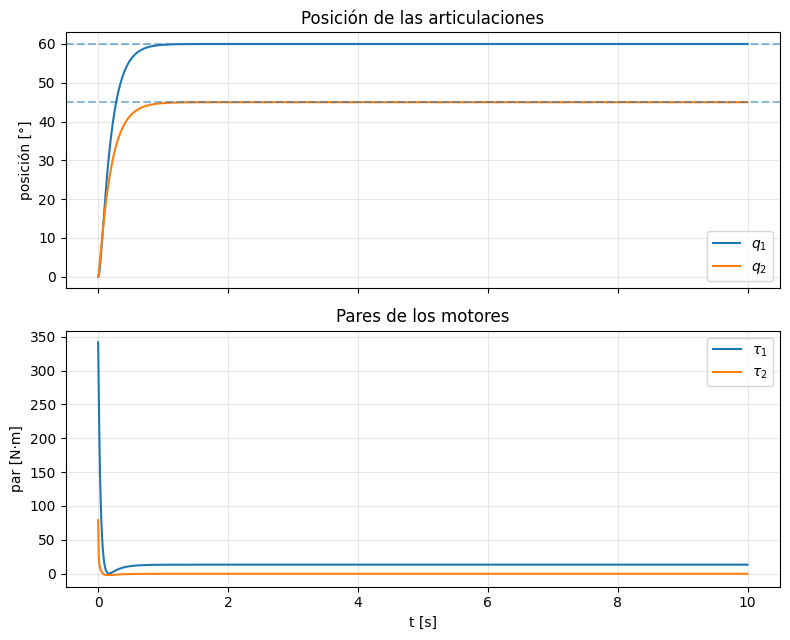

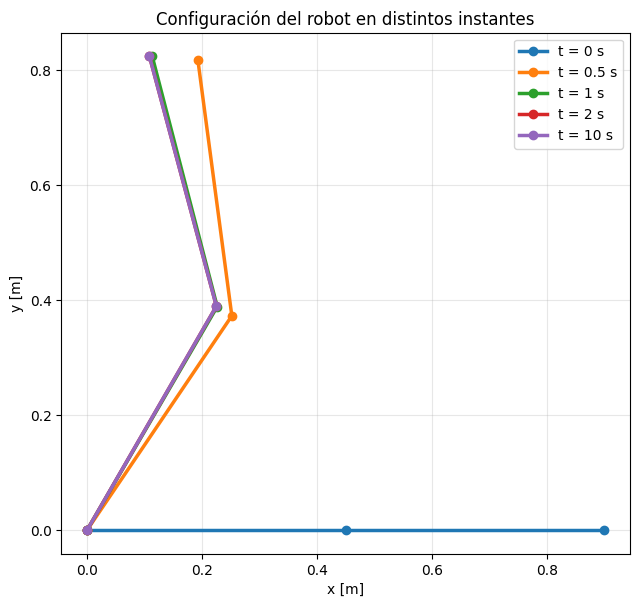

In [3]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ==========================================
# 1. Parámetros del robot (Tabla 5.1)
# ==========================================
l1 = 0.450      # Longitud eslabón 1 [m]
l2 = 0.450      # Longitud eslabón 2 [m]
lc1 = 0.091     # Distancia a CM1 [m]
lc2 = 0.048     # Distancia a CM2 [m]
m1 = 23.902     # Masa eslabón 1 [kg]
m2 = 1.285      # Masa eslabón 2 [kg]
I1 = 1.266      # Inercia eslabón 1 [kg·m²]
I2 = 0.093      # Inercia eslabón 2 [kg·m²]
b1 = 2.288      # Fricción viscosa art. 1 [N·m·s/rad]
b2 = 0.175      # Fricción viscosa art. 2 [N·m·s/rad]
g = 9.81        # Gravedad [m/s²]

# ==========================================
# 2. Controlador PD + compensación de gravedad
# ==========================================
qd = np.array([np.deg2rad(60.0), np.deg2rad(45.0)])  # Posición deseada [rad]
Kp = np.diag([300.0, 100.0])                         # Ganancia proporcional [N·m/rad]
Kv = np.diag([60.0, 20.0])                           # Ganancia derivativa [N·m·s/rad]


def vector_gravedad(q):
    """Calcula el vector de gravedad g(q)."""
    q1, q2 = q
    g1 = (m1 * lc1 + m2 * l1) * g * np.cos(q1) + m2 * lc2 * g * np.cos(q1 + q2)
    g2 = m2 * lc2 * g * np.cos(q1 + q2)
    return np.array([g1, g2])


def ley_control(q, dq):
    """Control PD con compensación de gravedad."""
    g_q = vector_gravedad(q)
    return Kp @ (qd - q) - Kv @ dq + g_q


def matrices_dinamicas(q, dq):
    """Calcula M(q), C(q, dq), g(q) y f(dq)."""
    q1, q2 = q
    dq1, dq2 = dq

    h = m2 * l1 * lc2 * np.sin(q2)

    # Matriz de inercia M(q)  <-- LÍNEA CORREGIDA
    M11 = m1 * lc1**2 + m2 * (l1**2 + lc2**2 + 2.0 * l1 * lc2 * np.cos(q2)) + I1 + I2
    M12 = m2 * (lc2**2 + l1 * lc2 * np.cos(q2)) + I2
    M22 = m2 * lc2**2 + I2
    M = np.array([[M11, M12],
                  [M12, M22]])

    # Matriz de Coriolis y fuerzas centrífugas C(q, dq)
    C = np.array([[-h * dq2, -h * (dq1 + dq2)],
                  [h * dq1,   0.0]])

    # Vector de gravedad g(q)
    g_q = vector_gravedad(q)

    # Vector de fricción viscosa f(dq)
    f_dq = np.array([b1 * dq1, b2 * dq2])

    return M, C, g_q, f_dq


def dinamica_robot(t, x):
    """Sistema de ecuaciones de primer orden dx/dt = f(t, x)."""
    q = x[:2]
    dq = x[2:]

    tau = ley_control(q, dq)
    M, C, g_q, f_dq = matrices_dinamicas(q, dq)

    ddq = np.linalg.solve(M, tau - C @ dq - g_q - f_dq)
    return np.concatenate((dq, ddq))


# ==========================================
# 3. Simulación numérica (10 s, RK45)
# ==========================================
t_span = (0.0, 10.0)
t_eval = np.linspace(t_span[0], t_span[1], 1001)
x0 = np.array([0.0, 0.0, 0.0, 0.0])  # q(0) = (0, 0), dq(0) = (0, 0)

sol = solve_ivp(
    dinamica_robot,
    t_span,
    x0,
    method="RK45",
    t_eval=t_eval,
    rtol=1e-8,
    atol=1e-10
)

t = sol.t
q1_deg = np.rad2deg(sol.y[0])
q2_deg = np.rad2deg(sol.y[1])

# Calcular pares aplicados a lo largo del tiempo
tau_hist = np.array([
    ley_control(sol.y[:2, k], sol.y[2:, k]) for k in range(len(t))
])

# ==========================================
# 4. Gráficas de resultados
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True)

ax1.plot(t, q1_deg, label=r"$q_1$")
ax1.plot(t, q2_deg, label=r"$q_2$")
ax1.axhline(60, linestyle="--", alpha=0.5)
ax1.axhline(45, linestyle="--", alpha=0.5)
ax1.set_ylabel("posición [°]")
ax1.set_title("Posición de las articulaciones")
ax1.grid(True, alpha=0.3)
ax1.legend()

ax2.plot(t, tau_hist[:, 0], label=r"$\tau_1$")
ax2.plot(t, tau_hist[:, 1], label=r"$\tau_2$")
ax2.set_xlabel("t [s]")
ax2.set_ylabel("par [N·m]")
ax2.set_title("Pares de los motores")
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()

# Configuración del robot en instantes clave
instantes = [0.0, 0.5, 1.0, 2.0, 10.0]
fig2, ax3 = plt.subplots(figsize=(6.5, 6.5))

for ti in instantes:
    idx = np.argmin(np.abs(t - ti))
    ang1 = sol.y[0, idx]
    ang2 = sol.y[1, idx]

    x_art1 = l1 * np.cos(ang1)
    y_art1 = l1 * np.sin(ang1)
    x_ef = x_art1 + l2 * np.cos(ang1 + ang2)
    y_ef = y_art1 + l2 * np.sin(ang1 + ang2)

    xs = [0.0, x_art1, x_ef]
    ys = [0.0, y_art1, y_ef]
    ax3.plot(xs, ys, marker="o", linewidth=2.5, label=f"t = {ti:g} s")

ax3.set_xlabel("x [m]")
ax3.set_ylabel("y [m]")
ax3.set_title("Configuración del robot en distintos instantes")
ax3.set_aspect("equal", adjustable="box")
ax3.grid(True, alpha=0.3)
ax3.legend()

plt.tight_layout()
plt.show()